# Análise de Segmentação de Clientes com Python

Este projeto tem como objetivo realizar uma análise exploratória de dados de clientes, buscando identificar características e padrões entre os diferentes segmentos de clientes (A, B, C e D). A análise será realizada utilizando Python, com foco em limpeza, organização, exploração e visualização dos dados, buscando obter informações que possam ajudar na compreensão do perfil e do comportamento dos clientes.

Link do Dataset: https://www.kaggle.com/datasets/vetrirah/customer?select=Train.csv


In [2]:
# Importar database
import pandas as pd

df_customer = pd.read_csv("train.csv")

df_customer.head(10)

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A
5,461319,Male,Yes,56,No,Artist,0.0,Average,2.0,Cat_6,C
6,460156,Male,No,32,Yes,Healthcare,1.0,Low,3.0,Cat_6,C
7,464347,Female,No,33,Yes,Healthcare,1.0,Low,3.0,Cat_6,D
8,465015,Female,Yes,61,Yes,Engineer,0.0,Low,3.0,Cat_7,D
9,465176,Female,Yes,55,Yes,Artist,1.0,Average,4.0,Cat_6,C


In [3]:
# Identificar problemas no dataset
print(df_customer.info())

# Número de linhas e colunas do dataset
df_customer.shape

<class 'pandas.DataFrame'>
RangeIndex: 8068 entries, 0 to 8067
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               8068 non-null   int64  
 1   Gender           8068 non-null   str    
 2   Ever_Married     7928 non-null   str    
 3   Age              8068 non-null   int64  
 4   Graduated        7990 non-null   str    
 5   Profession       7944 non-null   str    
 6   Work_Experience  7239 non-null   float64
 7   Spending_Score   8068 non-null   str    
 8   Family_Size      7733 non-null   float64
 9   Var_1            7992 non-null   str    
 10  Segmentation     8068 non-null   str    
dtypes: float64(2), int64(2), str(7)
memory usage: 693.5 KB
None


(8068, 11)

In [4]:
# Número de valores vazios em cada coluna
df_customer.isnull().sum()

ID                   0
Gender               0
Ever_Married       140
Age                  0
Graduated           78
Profession         124
Work_Experience    829
Spending_Score       0
Family_Size        335
Var_1               76
Segmentation         0
dtype: int64

In [5]:
# Quantidade de linhas com valores duplicados 
df_customer.duplicated().sum()

np.int64(0)

In [6]:
# Tratamento de valores ausentes

# Da coluna Ever_Married
print(df_customer["Ever_Married"].mode())
df_customer["Ever_Married"] = df_customer["Ever_Married"].fillna(df_customer["Ever_Married"].mode()[0])

# Da coluna Graduated
print(df_customer["Graduated"].mode())
df_customer["Graduated"] = df_customer["Graduated"].fillna(df_customer["Graduated"].mode()[0])

# Da coluna Profession
print(df_customer["Profession"].mode())
df_customer["Profession"] = df_customer["Profession"].fillna(df_customer["Profession"].mode()[0])

# Da coluna Work_Experience
print(df_customer["Work_Experience"].median())
df_customer["Work_Experience"] = df_customer["Work_Experience"].fillna(df_customer["Work_Experience"].median())

# Da coluna Family_Size
print(df_customer["Family_Size"].median())
df_customer["Family_Size"] = df_customer["Family_Size"].fillna(df_customer["Family_Size"].median())

# Remover a linhas que tiverem com o Var_1 vazio
df_customer.dropna(subset=['Var_1', 'Graduated'], inplace=True)


0    Yes
Name: Ever_Married, dtype: str
0    Yes
Name: Graduated, dtype: str
0    Artist
Name: Profession, dtype: str
1.0
3.0


In [7]:
# Verificar as colunas vazias que foram corrigidas
df_customer.isnull().sum()

ID                 0
Gender             0
Ever_Married       0
Age                0
Graduated          0
Profession         0
Work_Experience    0
Spending_Score     0
Family_Size        0
Var_1              0
Segmentation       0
dtype: int64

# Análise geral dos clientes

In [8]:
# Idade média dos clientes
print("A média da idade dos clientes é ",int(df_customer['Age'].median()),"anos")

# Menor e maior idade
print("A menor idade é", df_customer["Age"].min(),"anos")
print("A maior idade é", df_customer["Age"].max(),"anos")


A média da idade dos clientes é  40 anos
A menor idade é 18 anos
A maior idade é 89 anos


In [9]:
# Quantos clientes são homens?
print("No dataset tem", (df_customer["Gender"]=='Male').sum(),"homens")

# Quantos clientes são mulheres?
print("No dataset tem", (df_customer["Gender"]=='Female').sum(),"mulheres")

# Qual gênero possui mais clientes?
df_customer["Gender"].value_counts()

# Qual é a porcentagem de cada gênero?
total_genero = len(df_customer)
porcentagem_homem = (df_customer["Gender"]=='Male').sum()/total_genero * 100
porcentagem_mulher = (df_customer["Gender"]=='Female').sum()/total_genero * 100
print(f"Total: {total_genero}\n"
      f"Porcentagem de homem: {porcentagem_homem:.2f}%\n"
      f"Porcentagem de mulher: {porcentagem_mulher:.2f}%")



No dataset tem 4382 homens
No dataset tem 3610 mulheres
Total: 7992
Porcentagem de homem: 54.83%
Porcentagem de mulher: 45.17%


In [10]:
# Quantidade de clientes casados e não casados
qtd_Casado = (df_customer["Ever_Married"]=="Yes").sum()
qtd_NaoCasado = (df_customer["Ever_Married"]=="No").sum()
print(f"{qtd_Casado} pessoas já casaram\n"
        f"{qtd_NaoCasado} pessoas nunca casaram")

4737 pessoas já casaram
3255 pessoas nunca casaram


In [11]:
# Quantidade de clientes que se formaram ou não
qtd_Formado = (df_customer["Graduated"]=="Yes").sum()
qtd_NaoFormado = (df_customer["Graduated"]=="No").sum()  
print(f"{qtd_Formado} pessoas se formaram \n"
        f"{qtd_NaoFormado} pessoas não se formaram")

5006 pessoas se formaram 
2986 pessoas não se formaram


In [12]:
# Quais profissões existem na base
df_customer["Profession"].value_counts()

Profession
Artist           2612
Healthcare       1317
Entertainment     943
Engineer          694
Doctor            683
Lawyer            617
Executive         594
Marketing         290
Homemaker         242
Name: count, dtype: int64

In [13]:
# Qual é a profissão mais frequente
df_customer["Profession"].value_counts().idxmax()

'Artist'

In [14]:
# Qual é a menos frequente
df_customer["Profession"].value_counts().idxmin()

'Homemaker'

In [15]:
# Quantos clientes existem em cada nível?
df_customer["Spending_Score"].value_counts()

Spending_Score
Low        4829
Average    1957
High       1206
Name: count, dtype: int64

In [16]:
# Qual nível é o mais frequente?
df_customer["Spending_Score"].value_counts().idxmax()

'Low'

In [17]:
# Qual é o menos frequente?
.idxdf_customer["Spending_Score"].value_counts()min()

SyntaxError: invalid syntax (1599836636.py, line 2)

In [ ]:
# Qual porcentagem dos clientes está em cada nível?
df_customer["Spending_Score"].value_counts(normalize=True) * 100

Spending_Score
Low        60.422923
Average    24.486987
High       15.090090
Name: proportion, dtype: float64

In [ ]:

df_customer["Family_Size"].value_counts()



Family_Size
2.0    2371
3.0    1808
1.0    1441
4.0    1367
5.0     603
6.0     212
7.0      96
8.0      50
9.0      44
Name: count, dtype: int64

In [ ]:
# Qual é o tamanho de família mais comum?
df_customer["Family_Size"].value_counts().head(1)

Family_Size
2.0    2371
Name: count, dtype: int64

In [ ]:
# Qual é o menor e o maior tamanho de família?
maior_familia = (df_customer["Family_Size"]).max()
menor_familia = (df_customer["Family_Size"]).min()
print(f"A maior tamanho de família é {maior_familia}\n"
        f"O menor tamanho da família é { menor_familia}")

A maior tamanho de família é 9.0
O menor tamanho da família é 1.0


In [ ]:
# Quantos clientes têm famílias pequenas, médias ou grandes?
media_familia = (df_customer["Family_Size"]).median()
qtd_menor_familia = (df_customer["Family_Size"]==menor_familia).sum()
qtd_media_familia = (df_customer["Family_Size"]==media_familia).sum()
qtd_maior_familia = (df_customer["Family_Size"]==maior_familia).sum()

print(f"{qtd_menor_familia} clientes tem família pequena\n"
        f"{qtd_media_familia} clientes tem família média\n"
        f"{qtd_maior_familia} clientes tem família grande\n")

1441 clientes tem família pequena
1808 clientes tem família média
44 clientes tem família grande



In [ ]:
# Qual é a média de pessoas por família?
total_pessoas_familia = df_customer["Family_Size"].mean()
print(f"A média de pessoas por família é {total_pessoas_familia:.2f}")


A média de pessoas por família é 2.86


In [ ]:
# Quantos clientes possuem cada quantidade de anos de experiência?
df_customer["Work_Experience"].value_counts()

Work_Experience
1.0     3153
0.0     2295
9.0      470
8.0      456
2.0      284
3.0      253
4.0      250
6.0      204
7.0      194
5.0      192
10.0      53
11.0      49
12.0      48
13.0      46
14.0      45
Name: count, dtype: int64

In [ ]:
# Qual é o tempo de experiência mais comum?
df_customer["Work_Experience"].value_counts().head(1)

Work_Experience
1.0    3153
Name: count, dtype: int64

In [ ]:
# Qual é o menor e o maior tempo de experiência?
menor_experiencia = (df_customer["Work_Experience"]).min()
maior_experiencia = (df_customer["Work_Experience"]).max()

print(f"O menor tempo de experiencia é {menor_experiencia}\n",
        f"O maior tempo de experiencia é {maior_experiencia}")


O menor tempo de experiencia é 0.0
 O maior tempo de experiencia é 14.0


In [ ]:
# Qual é a média de anos de experiência?
media_experiencia = df_customer["Work_Experience"].mean()
print(f"A média é {media_experiencia:.2f} anos de experiencia")

A média é 2.47 anos de experiencia


# Análise dos segmentos

In [ ]:
# Quantos clientes existem em cada segmento
df_customer["Segmentation"].value_counts()

Segmentation
D    2245
A    1953
C    1949
B    1845
Name: count, dtype: int64

In [ ]:
# Qual segmento possui mais clientes
df_customer["Segmentation"].value_counts().idxmax()

'D'

In [ ]:
# Qual segmento possui menos clientes
df_customer["Segmentation"].value_counts().idxmin()


'B'

In [ ]:
# Percentual de clientes em cada segmento
df_customer["Segmentation"].value_counts(normalize=True)*100

Segmentation
D    28.090591
A    24.436937
C    24.386887
B    23.085586
Name: proportion, dtype: float64

In [ ]:
# qual segmento tem clientes mais velhos ou mais jovens?
med_seg_idade = df_customer.groupby("Segmentation")["Age"].mean()
print(med_seg_idade)

maior_seg_idade = med_seg_idade.idxmax()
print(f"O {maior_seg_idade} é o segmento com clientes mais velhos")

menor_seg_idade = med_seg_idade.idxmin()
print(f"O {menor_seg_idade} é o segmento com clientes mais novos")



Segmentation
A    44.885305
B    48.240650
C    49.178040
D    33.332294
Name: Age, dtype: float64
O C é o segmento com clientes mais velhos
O D é o segmento com clientes mais novos


In [ ]:
# comparar homens e mulheres dentro de A, B, C e D
qtd_seg_gender = df_customer.groupby(["Segmentation","Gender"]).size().unstack()
print(qtd_seg_gender)



Gender        Female  Male
Segmentation              
A                901  1052
B                852   993
C                911  1038
D                946  1299


In [ ]:
# Qual o gênero com a maior número de clientes em cada gênero?
# O axis compara as colunas da mesma linha
maior_seg_gender = qtd_seg_gender.idxmax(axis=1)
print(maior_seg_gender)

Segmentation
A    Male
B    Male
C    Male
D    Male
dtype: str


In [ ]:
# Qual o gênero com o menor número de clientes em cada segmento?
menor_seg_gender = qtd_seg_gender.idxmin(axis=1)
print(menor_seg_gender)

Segmentation
A    Female
B    Female
C    Female
D    Female
dtype: str


In [ ]:
# Comparar Yes e No de Ever_Married dentro de cada segmento
qtd_seg_marry = df_customer.groupby(["Segmentation","Ever_Married"]).size().unstack()
print(qtd_seg_marry)

Ever_Married    No   Yes
Segmentation            
A              794  1159
B              476  1369
C              391  1558
D             1594   651


In [ ]:
# Qual o Ever_Married com a maior número de clientes em cada segmento?
maior_seg_marry = qtd_seg_marry.idxmax(axis=1)
print(maior_seg_marry)

Segmentation
A    Yes
B    Yes
C    Yes
D     No
dtype: str


In [ ]:
# Qual o Ever_Married com a maior número de clientes em cada segmento?
menor_seg_marry = qtd_seg_marry.idxmin(axis=1)
print(menor_seg_marry)

Segmentation
A     No
B     No
C     No
D    Yes
dtype: str


In [ ]:
# Quantidade de profissões de cada segmento
qtd_seg_prof = df_customer.groupby(["Segmentation","Profession"]).size().unstack()
print(qtd_seg_prof)

Profession    Artist  Doctor  Engineer  Entertainment  Executive  Healthcare  \
Segmentation                                                                   
A                587     196       257            362        123         106   
B                769     143       188            221        182         100   
C               1071     139        74            148        175         142   
D                185     205       175            212        114         969   

Profession    Homemaker  Lawyer  Marketing  
Segmentation                                
A                    71     194         57  
B                    54     158         30  
C                    28     138         34  
D                    89     127        169  


In [ ]:
# descobrir quais profissões são mais comuns em cada segmento
maior_seg_prof = qtd_seg_prof.idxmax(axis=1)
print(maior_seg_prof)

Segmentation
A        Artist
B        Artist
C        Artist
D    Healthcare
dtype: str


In [ ]:
# Quantidade de clientes em cada Spending_Score em cada Segmento
qtd_seg_score = df_customer.groupby(["Segmentation","Spending_Score"]).size().unstack()
print(qtd_seg_score)

Spending_Score  Average  High   Low
Segmentation                       
A                   339   269  1345
B                   586   379   880
C                   895   403   651
D                   137   155  1953


In [ ]:
# Comparar Low, Average e High dentro de cada segmento
# Com maior quantidade de cliente em cada segmento
maior_seg_score = qtd_seg_score.idxmax(axis=1)
print(maior_seg_score)


Segmentation
A        Low
B        Low
C    Average
D        Low
dtype: str


In [ ]:
# Com menor quantidade de cliente em cada segmento
menor_seg_score = qtd_seg_score.idxmin(axis=1)
print(menor_seg_score)

Segmentation
A       High
B       High
C       High
D    Average
dtype: str


# Comparação de idade entre segmentos

In [ ]:
# Distribuição das idades em cada segmento
df_customer.groupby(["Age","Segmentation"]).size().unstack()

Segmentation,A,B,C,D
Age,,,,
18,3,4,3,122
19,8,1,5,119
20,4,4,8,109
21,3,4,7,100
22,6,5,4,126
...,...,...,...,...
85,8,1,3,9
86,10,7,9,3
87,14,4,9,1


In [ ]:
# Verificar se determinado segmento concentra clientes mais jovens ou mais velhos
media_seg = df_customer.groupby("Segmentation")["Age"].mean()
print(media_seg)
print(f"O segmento mais velho é {media_seg.idxmax()}\n",
      f"O segmento mais novo é {media_seg.idxmin()}")


Segmentation
A    44.885305
B    48.240650
C    49.178040
D    33.332294
Name: Age, dtype: float64
O segmento mais velho é C
 O segmento mais novo é D


# Análise Gênero × Segmento

In [ ]:
# Qual gênero é predominante em cada segmento?
seg_genero = df_customer.groupby(["Segmentation","Gender"]).size().unstack().idxmax(axis=1)
print(seg_genero)

Segmentation
A    Male
B    Male
C    Male
D    Male
dtype: str


# Análise Profissão × Segmento

In [ ]:
# Quais profissões aparecem mais em cada segmento?
seg_prof = df_customer.groupby(["Segmentation","Profession"]).size().unstack().idxmax(axis=1)
print(seg_prof)

Segmentation
A        Artist
B        Artist
C        Artist
D    Healthcare
dtype: str


In [ ]:
# Qual profissão é mais comum no segmento A?
seg_prof_A = df_customer.groupby(["Segmentation", "Profession"]).size().unstack().idxmax(axis=1)["A"]
print(f"{seg_prof_A} é a profissão mais comum no segmento A")

Artist é a profissão mais comum no segmento A


In [ ]:
# E a B?
seg_prof_B = df_customer.groupby(["Segmentation", "Profession"]).size().unstack().idxmax(axis=1)["B"]
print(f"{seg_prof_B} é a profissão mais comum no segmento B")

Artist é a profissão mais comum no segmento B


In [ ]:
# E a C?
seg_prof_C = df_customer.groupby(["Segmentation", "Profession"]).size().unstack().idxmax(axis=1)["C"]
print(f"{seg_prof_C} é a profissão mais comum no segmento C")

Artist é a profissão mais comum no segmento C


In [ ]:
# E a D?
seg_prof_D = df_customer.groupby(["Segmentation", "Profession"]).size().unstack().idxmax(axis=1)["D"]
print(f"{seg_prof_D} é a profissão mais comum no segmento D")

Healthcare é a profissão mais comum no segmento D


In [ ]:
# Existem profissões pouco representadas em algum segmento?
seg_prof = df_customer.groupby(["Segmentation","Profession"]).size().unstack().idxmin(axis=1)
print(seg_prof)

Segmentation
A    Marketing
B    Marketing
C    Homemaker
D    Homemaker
dtype: str


# Análise do Spending Score × Segmento

In [ ]:
# Quantos clientes de cada segmento possuem Low?
seg_score_low = df_customer.groupby(["Segmentation","Spending_Score"]).size().unstack()["Low"]
print(seg_score_low)


Segmentation
A    1345
B     880
C     651
D    1953
Name: Low, dtype: int64


In [ ]:
# Quantos possuem Average?
seg_score_average = df_customer.groupby(["Segmentation","Spending_Score"]).size().unstack()["Average"]
print(seg_score_average)

Segmentation
A    339
B    586
C    895
D    137
Name: Average, dtype: int64


In [ ]:
# Quantos possuem High?
seg_score_high = df_customer.groupby(["Segmentation","Spending_Score"]).size().unstack()["High"]
print(seg_score_high)

Segmentation
A    269
B    379
C    403
D    155
Name: High, dtype: int64


In [ ]:
# Qual segmento possui maior proporção de clientes com alto consumo?
seg_score_high = df_customer.groupby(["Segmentation","Spending_Score"]).size().unstack().idxmax()["High"]
print(f"{seg_score_high} é o segmento que possui maior proporção de clientes de alto consumo")

C é o segmento que possui maior proporção de clientes de alto consumo


In [ ]:
# Qual segmento possui maior proporção de clientes com baixo consumo?
seg_score_low = df_customer.groupby(["Segmentation","Spending_Score"]).size().unstack().idxmax()["Low"]
print(f"{seg_score_low} é o segmento que possui a maior proporção de clientes com baixo consumo")

D é o segmento que possui a maior proporção de clientes com baixo consumo


# Gráfico de Barras (Contagem por Segmento)

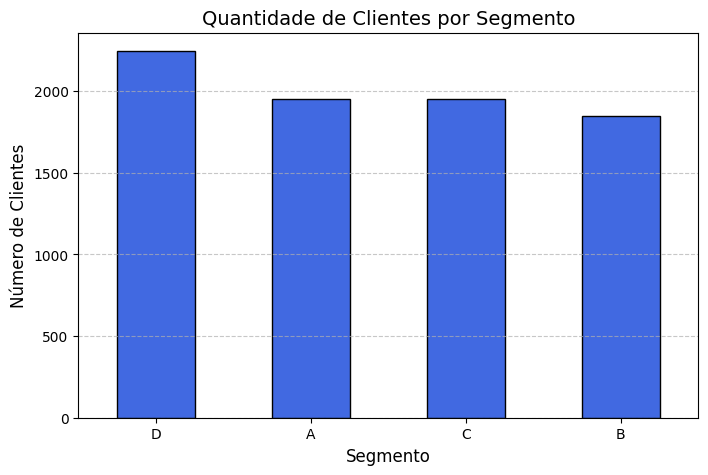

In [20]:
import matplotlib.pyplot as plt

# Configurando o tamanho da figura
plt.figure(figsize=(8, 5))

# Criando o gráfico de barras
df_customer['Segmentation'].value_counts().plot(kind='bar', color='royalblue', edgecolor='black')

# Adicionando títulos e rótulos
plt.title('Quantidade de Clientes por Segmento', fontsize=14)
plt.xlabel('Segmento', fontsize=12)
plt.ylabel('Número de Clientes', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)


plt.show()

# Gráfico de Pizza (Proporção de Gênero)

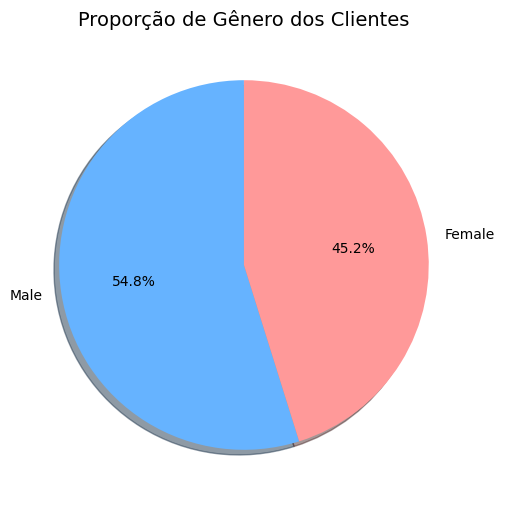

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))

# Criando o gráfico de pizza com porcentagem
df_customer['Gender'].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['#66b3ff','#ff9999'],shadow=True)
plt.title('Proporção de Gênero dos Clientes', fontsize=14)
plt.ylabel('') 

plt.show()

# Gráfico de Barras Empilhado (Segmento × Nível de Gastos)

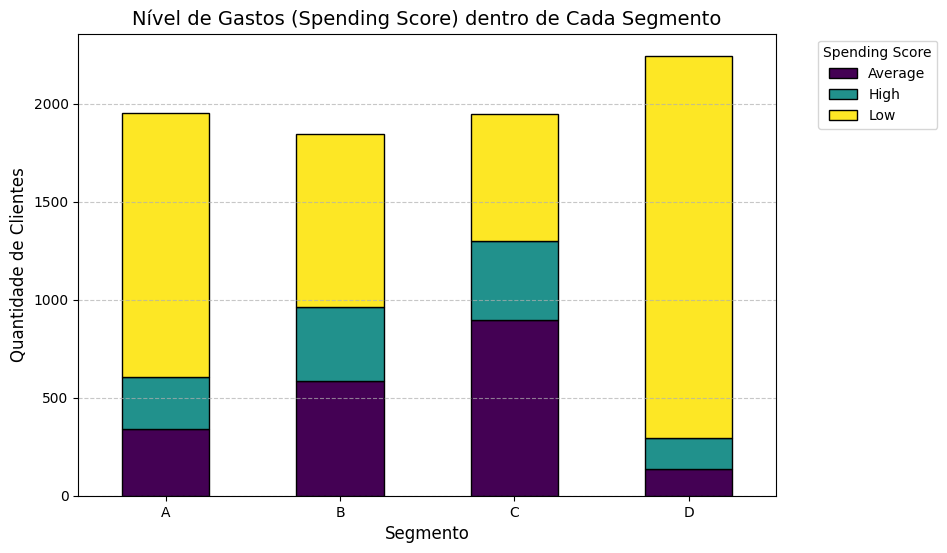

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

tabela_score = pd.crosstab(df_customer['Segmentation'], df_customer['Spending_Score'])

tabela_score.plot(kind='bar', stacked=True, figsize=(9, 6), colormap='viridis', edgecolor='black')

plt.title('Nível de Gastos (Spending Score) dentro de Cada Segmento', fontsize=14)
plt.xlabel('Segmento', fontsize=12)
plt.ylabel('Quantidade de Clientes', fontsize=12)
plt.legend(title='Spending Score', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()